In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("smartcart_customers.csv")
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,42,118,247,2,9,3,4,5,0,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,0,0,8,7,8,2,5,7,0,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,32,12,24,1,2,3,13,6,0,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,80,30,61,2,6,5,10,3,0,0


In [3]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

#datapreprocessing

 #### 1. handle missing value 

In [4]:
df["Income"]=df["Income"].fillna(df["Income"].median())

### feature engineering

In [5]:
#meaningful data is age 
df["Age"]=2026-df["Year_Birth"]

#tenure 
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"],dayfirst=True)
reference_date = df["Dt_Customer"].max()
df["customer_Tenure_Days"] = (reference_date-df["Dt_Customer"]).dt.days

In [6]:
#spending

df["Total_Spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]

In [7]:
#children
df["Total_Children"] = df["Kidhome"]+df["Teenhome"]

In [8]:
#education
df["Education"]=df["Education"].replace({
    "Basic":"Undergraduate","2n Cycle":"Undergraduate","Graduation":"Graduate","PhD":"Postgraduate","Master":"Postgraduate"
})


In [9]:
df["Living_status"]=df["Marital_Status"].replace({
    "Married":"Partner","Together":"Partner",
    "Single":"Alone","Divorced":"Alone",
    "Widow":"Alone","Absurd":"Alone","YOLO":"Alone"
})

### drop columns

In [10]:
cols=["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]
spending_cols=['MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds']
allDrop=cols+spending_cols
df_clean = df.drop(columns=allDrop)

### detecting and removing outliers

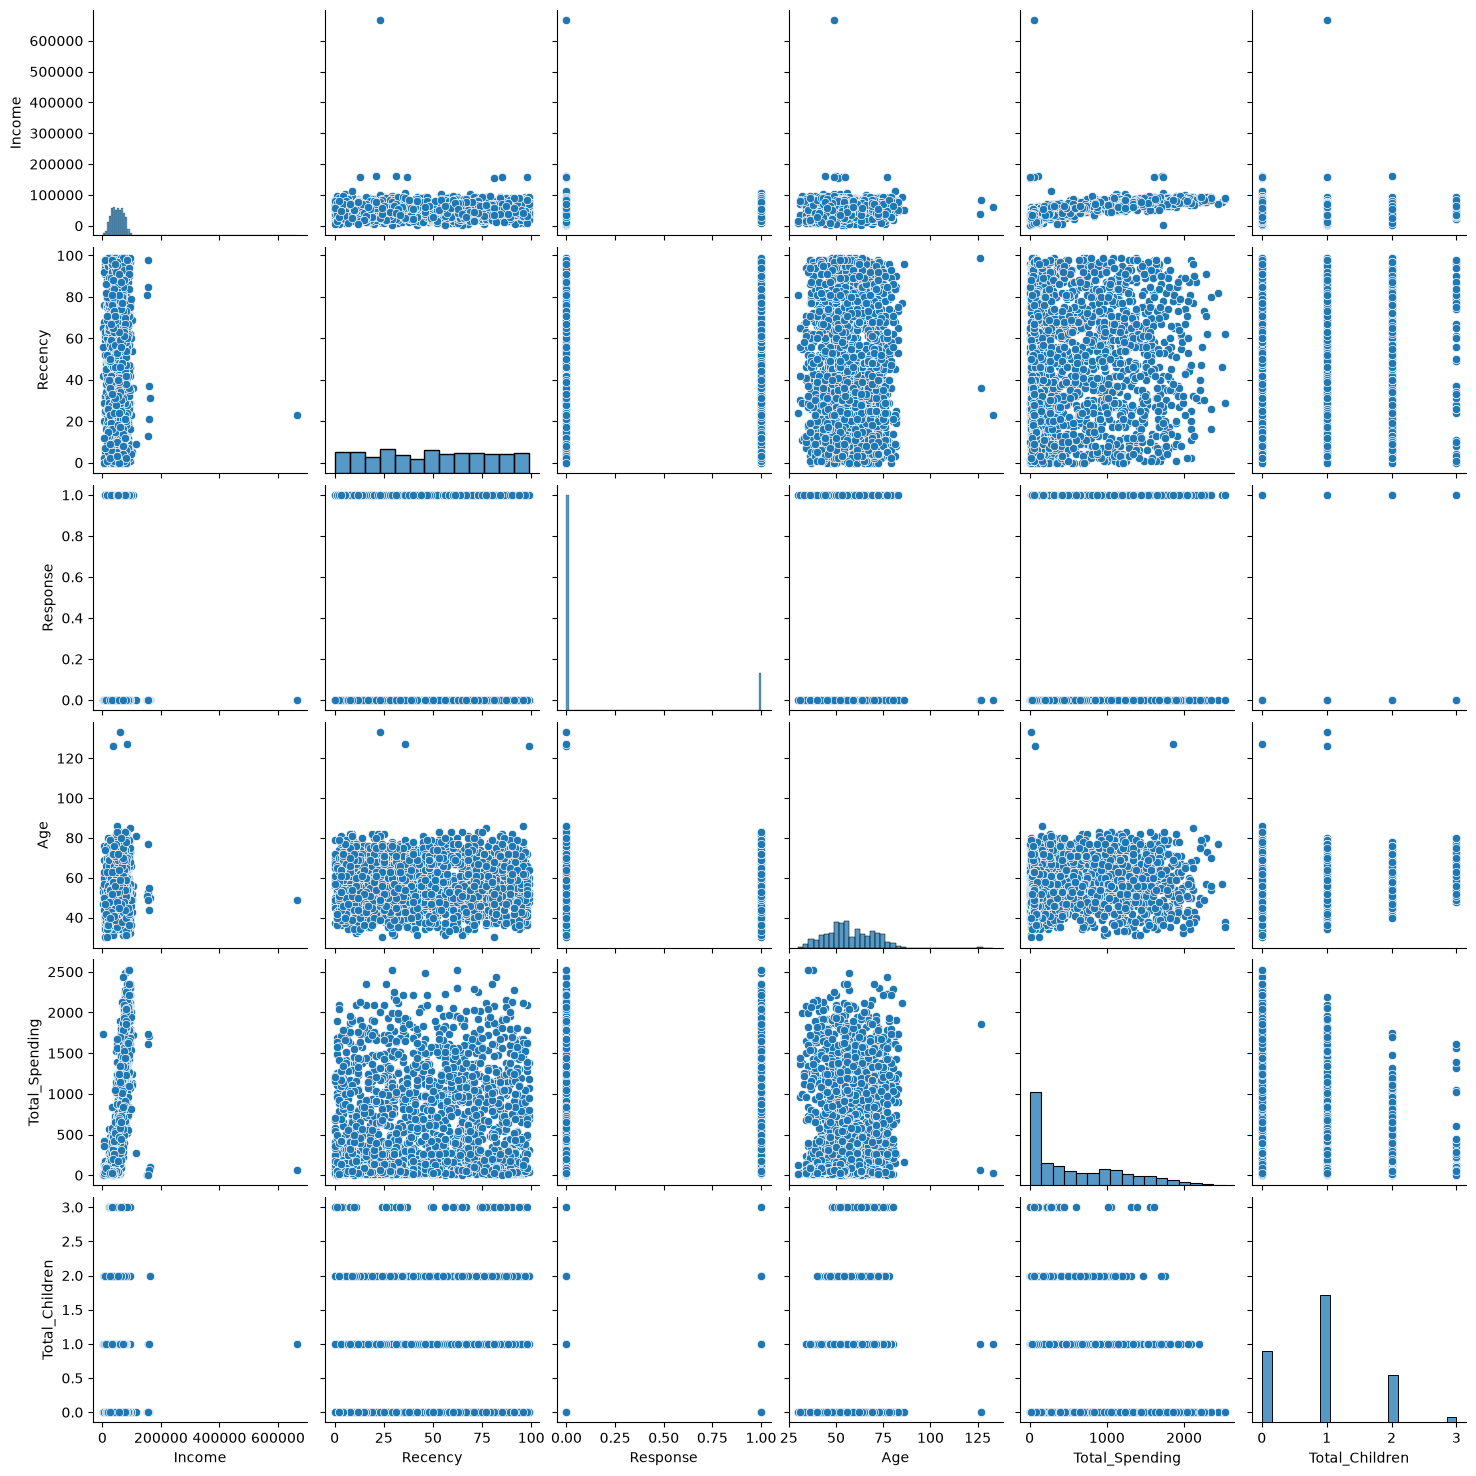

In [11]:
cols=["Income","Recency","Response","Age","Total_Spending","Total_Children"]
sns.pairplot(df_clean[cols])

In [12]:
#outlier removal 
df_clean = df_clean[df_clean["Age"]<90]
df_clean = df_clean[df_clean["Income"]<600000]


### Heatmap / correlation metrics

<Axes: >

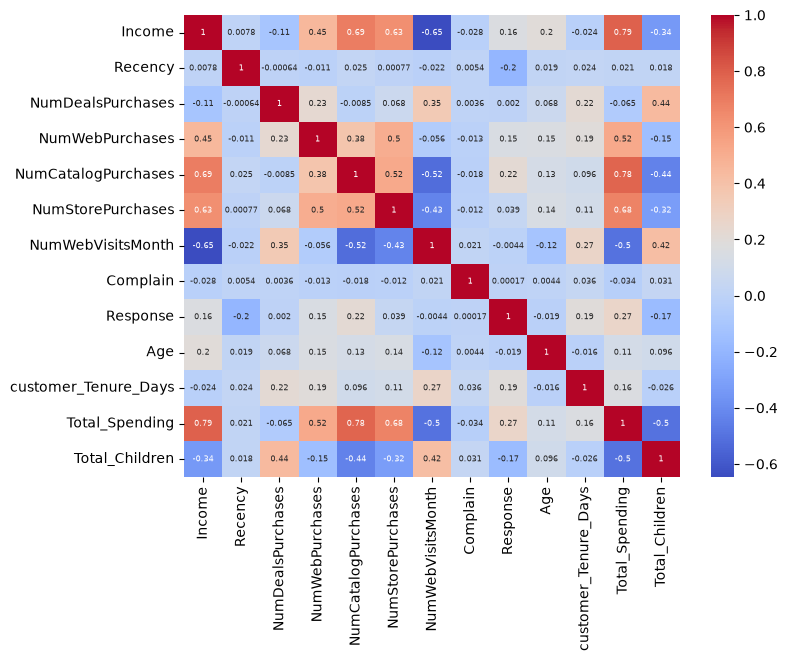

In [13]:
corr=df_clean.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

#### encoding

In [14]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder()

cat_cols=["Education","Living_status"]
enc_cols=ohe.fit_transform(df_clean[cat_cols])
enc_df=pd.DataFrame(enc_cols.toarray(), 
             columns=ohe.get_feature_names_out(cat_cols),
             index=df_clean.index
            )

df_enc = pd.concat([df_clean.drop(columns=cat_cols),enc_df],axis=1)
df_enc.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_status_Alone,Living_status_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


#### scaling

In [15]:
from sklearn.preprocessing import StandardScaler
X=df_enc
scaler = StandardScaler()
X_scaled=scaler.fit_transform(X)

#### visualization

C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\collections.py:1115: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


Text(0.5, 0.92, '3d Projection')

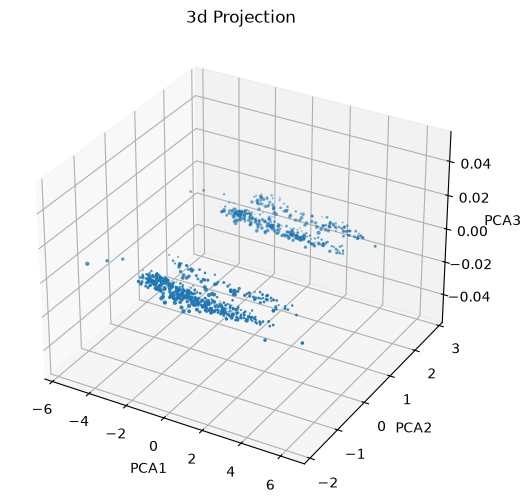

In [16]:
from sklearn.decomposition import PCA
pca=PCA(n_components=3)

x_pca = pca.fit_transform(X_scaled)

fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

plt.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3d Projection")

# Anlyze the K value 
## 1.elbow method

best k :  4


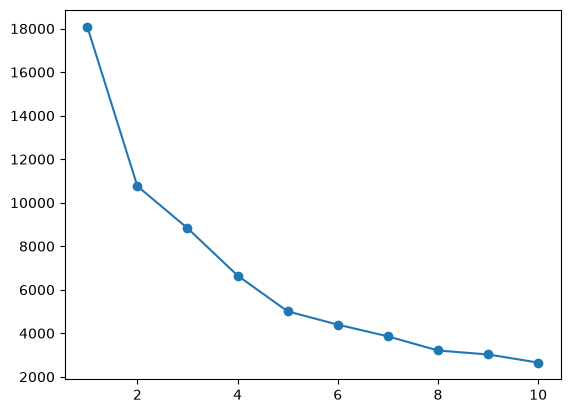

In [23]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

WCSS  = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(x_pca)
    WCSS.append(kmeans.inertia_)
    
knee=KneeLocator(range(1,11),WCSS,curve="convex",direction="decreasing")
optimal_k = knee.elbow
print("best k : ", optimal_k)
plt.plot(range(1,11),WCSS,marker="o")

## 2. silhouette score 

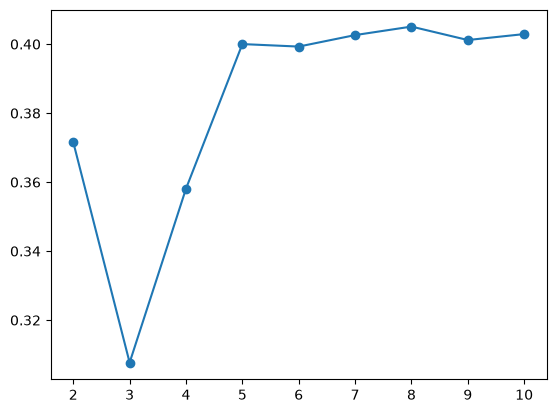

In [26]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k,random_state=42)
    labels = kmeans.fit_predict(x_pca)
    score = silhouette_score(x_pca,labels)
    scores.append(score)

plt.plot(range(2,11),scores,marker="o")


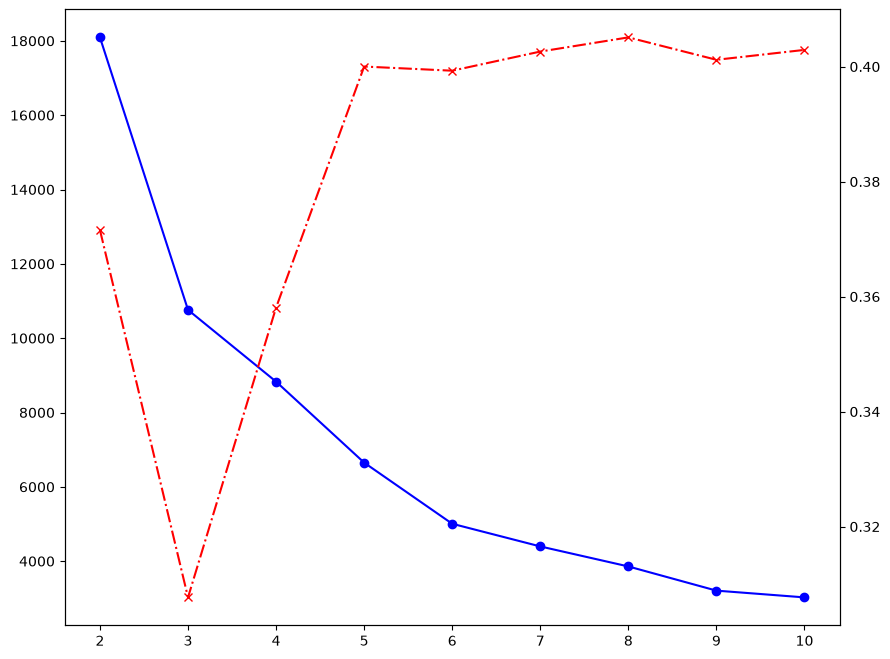

In [49]:
#combined plot 
k_range=range(2,11)
length=len(k_range)
fig,ax1 = plt.subplots(figsize=(10,8))

ax1.plot(k_range,WCSS[:length],marker="o",color="blue")

ax2 = ax1.twinx()
ax2.plot(k_range,scores[:length],marker="x",color="red", linestyle="-.")

## clustering

C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\collections.py:1115: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


Text(0.5, 0.92, '3d Projection')

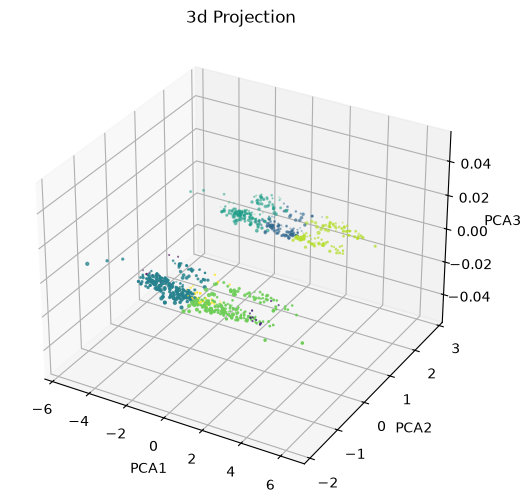

In [52]:
# k means 

kmeans = KMeans(n_clusters=4,random_state=42)
labels_kmeans = kmeans.fit_predict(x_pca)

fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

plt.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2], c=labels)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3d Projection")

C:\Users\admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\collections.py:1115: RuntimeWarning: invalid value encountered in sqrt
  scale = np.sqrt(self._sizes) * dpi / 72.0 * self._factor


Text(0.5, 0.92, 'Agglomerative Clustering ')

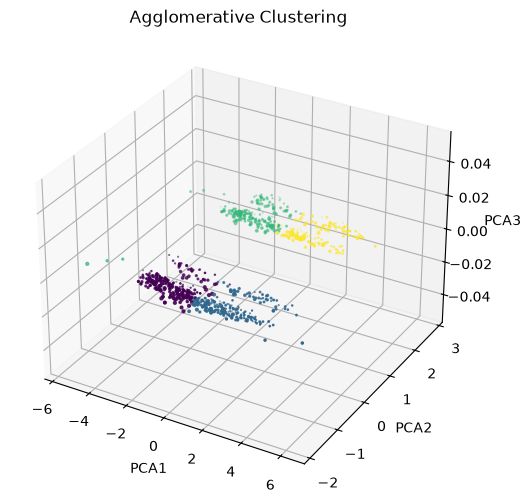

In [54]:
#agglomerative clustering

from sklearn.cluster import AgglomerativeClustering

agg_cls = AgglomerativeClustering(n_clusters=4,linkage="ward")
labels_agg = agg_cls.fit_predict(x_pca)


fig = plt.figure(figsize=(8,6))

ax = fig.add_subplot(111,projection="3d")

plt.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=labels_agg)


ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("Agglomerative Clustering ")

## characterization of clusters

In [63]:
# df_clean.drop("labels",axis=1)
X["cluster"] = labels_agg

<Axes: xlabel='cluster', ylabel='count'>

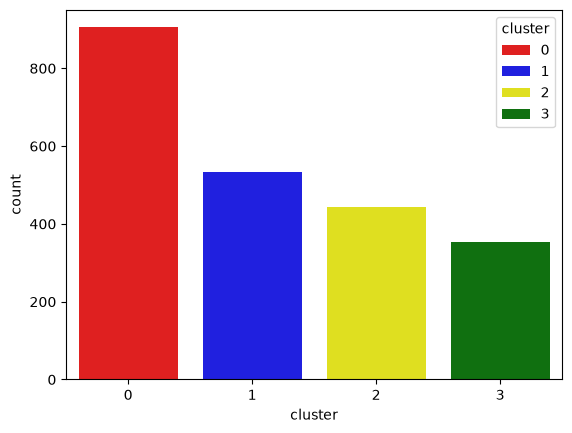

In [64]:
palette = ["red","blue","yellow","green"]

sns.countplot(x=X["cluster"],palette=palette,hue=X["cluster"])

#### income and spending pattern 

<Axes: xlabel='Total_Spending', ylabel='Income'>

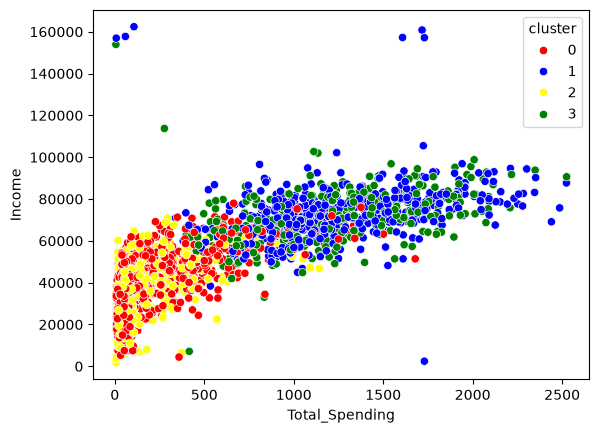

In [65]:
sns.scatterplot(x=df_clean["Total_Spending"],y=X["Income"],hue=X["cluster"],palette=palette)

## red -> low/moderate income - low/moderate  spending 

## blue -> high income , high spending

## yellow -> low income , low spending 

## green -> moderate income , high spending 

# cluster summary 

In [67]:
cluster_summary = X.groupby("cluster").mean()
print(cluster_summary)

               Income    Recency  NumDealsPurchases  NumWebPurchases  \
cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  customer_Tenure_Days  Total_Spending  \
cluster         

In [20]:
df["Living_status"].value_counts()

Living_status
Partner    1444
Alone       796
Name: count, dtype: int64

In [21]:
df_clean.columns

Index(['Education', 'Income', 'Recency', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'Complain', 'Response', 'Age',
       'customer_Tenure_Days', 'Total_Spending', 'Total_Children',
       'Living_status'],
      dtype='str')